# 02 — Experiment 1 (Candidate B): estimating acceleration–speed capacity from game tracking — controlled simulation

**Question.** Can we estimate an athlete's maximal-speed capacity **S0** and maximal-acceleration capacity **A0** from
game-style tracking, where athletes rarely move at their limits, the data are noisy, and the samples come at 10 Hz?

**Guardrails.**
- Synthetic data with known ground truth only; **no NFL outcome data** are used anywhere.
- Real competition data are used *only* to make the simulator realistic: combine-40 velocity curves, exposure counts and tracking-noise statistics.
- The estimator was designed on **development seeds 101–103**; all reported results use **disjoint evaluation seeds** (see `scripts/run_capacity_simulation.py`).
- **Simulated improvements do not establish real-world validity.**

Contents:
1. Reviewed methods and their assumptions.
2. Generator and its calibration.
3. Design history on development seeds (including failed designs).
4. Evaluation: bias, RMSE, robustness, calibration, data sensitivity.
5. Conclusions and unvalidatable assumptions.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
import numpy as np, polars as pl, matplotlib.pyplot as plt
from nfl_bdb.visualization import style
from nfl_bdb.simulation.movement import GameSimConfig, simulate_game_tracks, kinematics_fast, sample_athletes
from nfl_bdb.models.capacity_estimator import (BASELINES, fit_binned, fit_simex, PooledCapacityEstimator,
    HierarchicalFrontierEstimator, HEFConfig, V_MIN)
style.apply(); pl.Config.set_tbl_rows(60); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_hide_dataframe_shape(True)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name): fig.savefig(FIG / f"sim_b_{name}.png", bbox_inches="tight", dpi=150)
run_id = (ROOT / "experiments/capacity_sim/LATEST").read_text().strip()
R = pl.read_parquet(ROOT / f"experiments/capacity_sim/{run_id}/results.parquet")
CFG = json.load(open(ROOT / f"experiments/capacity_sim/{run_id}/config.json"))
print("evaluation run:", run_id, "| rows:", R.height, "| cells:", R["cell"].n_unique(), "| replicates per cell:", R["rep"].n_unique())

evaluation run: 20261120T195416Z | rows: 119000 | cells: 24 | replicates per cell: 5


## 1 · Reviewed estimation methods and their mathematical assumptions

All methods target the **linear acceleration–speed (A–S) frontier** a_max(v) = A0 (1 − v/S0). This is the Hill–Keller sprint model behind the in-situ A–S profile (Morin et al. 2021). Inputs are frames with speed v ≥ 3 m/s (3.28 yd/s) and tangential acceleration a > 0.

| Method | Source (access) | Estimator | Key assumptions |
|---|---|---|---|
| Max observed | naive | S0 = max v, A0 = max a | athlete reached S0 and A0 in the data; no noise |
| Binned (Morin) | Morin et al. 2021, abstract | max a in each 0.2 m/s bin; OLS line through the maxima | each bin contains ≥1 near-maximal frame; frontier linear; noise negligible relative to the max |
| Binned + CI rule | Cormier et al. 2023, abstract | drop bin maxima outside the 95% prediction band, refit | the outlying maxima are artefacts |
| Binned + boxplot rule | Cormier et al. 2023, abstract (our reading) | Tukey upper fence within bins before taking the max | artefacts are upper outliers of the within-bin distribution |
| DBSCAN + binned | inspired by Miguens et al. 2024, abstract | density clustering removes isolated points, then binning | artefacts are low-density points |
| Quantile regression | Koenker & Bassett 1978 (metadata) | linear τ-quantile (τ = 0.99) of a on v | the frontier is a fixed high quantile; ignores exposure differences across speeds |
| **NCP-AS (proposed)** | this work | Morin binning → **SIMEX** noise correction (Cook & Stefanski 1994) → play-jackknife SE → **empirical-Bayes shrinkage** within position | position noise is white with known/estimable SD; SIMEX extrapolant (quadratic) adequate; normal–normal pooling |

The published procedures were known to us **from abstracts only**, so the baselines are our implementations of the described rules, not replications.

**Why SIMEX.** Measurement noise in derived acceleration *inflates bin maxima*, most of all at high speed, where the true frontier acceleration is small. That flattens the fitted line and inflates S0. SIMEX adds extra noise of known variance, records how the estimate drifts, and extrapolates back to zero noise. It needs the noise SD, which we estimate from real data (§2.3).

## 2 · Generator and calibration
### 2.1 Ground-truth capacities from real combine 40s (mono-exponential fits; no outcomes)

In [2]:
from scipy.optimize import curve_fit
sys.path.insert(0, str(ROOT / "src"))
from nfl_bdb.data.io import load
ct = load("combine_tracking", lazy=False).filter((pl.col("entity_type")=="PLAYER") & (pl.col("drill_type")=="FORTY_YARD_DASH")).sort("event_id","time")
pos = load("combine_results", lazy=False).select("nfl_id","combine_position")
mono = lambda t,S0,tau,t0: np.where(t>t0, S0*(1-np.exp(-(t-t0)/tau)), 0.0)
rows=[]
for (eid,nid),g in ct.group_by(["event_id","nfl_id"]):
    s=g["s"].to_numpy(); t=np.arange(len(s))/10; ip=int(np.argmax(s))
    if ip<15: continue
    try:
        p,_=curve_fit(mono,t[:ip+1],s[:ip+1],p0=[s.max(),1.0,t[np.argmax(s>0.3)]],bounds=([5,0.3,-1],[14,3,3]),maxfev=5000)
        r2=1-np.sum((s[:ip+1]-mono(t[:ip+1],*p))**2)/np.sum((s[:ip+1]-s[:ip+1].mean())**2)
        rows.append((nid,p[0],p[1],p[0]/p[1],s.max(),r2))
    except Exception: pass
fits=pl.DataFrame(rows,schema=["nfl_id","S0","tau","A0","vpeak","r2"],orient="row").join(pos,on="nfl_id")
print(f"attempts fitted: {fits.height}; median R² = {fits['r2'].median():.4f}; share R² > 0.98 = {(fits['r2']>0.98).mean():.3f}")
best=fits.sort("vpeak",descending=True).group_by("nfl_id").first()
best.group_by("combine_position").agg(pl.len().alias("n"), pl.col("S0").mean().round(2).alias("S0_mean"), pl.col("S0").std().round(2).alias("S0_sd"),
    pl.col("A0").mean().round(2).alias("A0_mean"), pl.col("A0").std().round(2).alias("A0_sd"), pl.col("tau").mean().round(2).alias("tau_mean")).sort("combine_position")

attempts fitted: 792; median R² = 0.9956; share R² > 0.98 = 0.990


combine_position,n,S0_mean,S0_sd,A0_mean,A0_sd,tau_mean
str,u32,f64,f64,f64,f64,f64
"""DB""",102,11.55,0.43,8.84,1.03,1.33
"""DL""",93,10.48,0.72,8.04,0.94,1.32
"""OL""",95,9.77,0.42,7.51,1.2,1.33
"""TE""",34,10.92,0.37,8.32,0.74,1.32
"""WR""",94,11.64,0.44,8.89,1.23,1.33


These per-position means and SDs (S0, A0) define the simulated athletes (`CALIB` in the runner).

**Assumptions not estimable from our data** (varied in sensitivity cells):
- the probability that an in-game effort is maximal, p_max: WR/DB 0.06, TE/DL 0.04, OL 0.015;
- braking capacity D;
- the effort-intensity distribution;
- that game and combine capacities are the same.

### 2.2 Exposure from real game tracking (counts only)

In [3]:
g = load("games").filter(pl.col("season_type")!="PRE").select("game_id")
ex = pl.concat([load(f"game_tracking_{y}").join(g,on="game_id").group_by("nfl_id","game_id","play_id").agg(pl.len().alias("frames")).collect() for y in (2023,2024,2025)])
pps = ex.group_by("nfl_id").agg(pl.len().alias("plays"))
print("REG+POST plays per player (all seasons) quantiles 10/25/50/75/90%:", [int(pps["plays"].quantile(q)) for q in (0.1,0.25,0.5,0.75,0.9)])
print("frames per play quantiles 5/50/95%:", [int(ex["frames"].quantile(q)) for q in (0.05,0.5,0.95)])

REG+POST plays per player (all seasons) quantiles 10/25/50/75/90%: [31, 111, 362, 982, 1657]
frames per play quantiles 5/50/95%: [51, 70, 103]


Simulated plays last a median of 7.0 s (log-SD 0.2), matching the real median of about 70 frames.
- Exposure cells span 10–500 plays per athlete.
- The `mixed_exposure` cell draws exposure from a log-normal fitted to the real player-season distribution (median 263, 10th–90th percentile 22–955; capped at 600).

### 2.3 Tracking-noise calibration (real vs simulated high-frequency statistics)
- Real game positions are vendor-smoothed: second differences are exactly 0 while players stand still.
- We match two robust statistics while running (4–8 yd/s): the robust SD of position second differences, Δ²x, and of speed second differences, Δ²s.

In [4]:
mad = lambda z: 1.4826*np.median(np.abs(z-np.median(z)))
k=["game_id","play_id","nfl_id"]
gt=load("game_tracking_2025").head(2_000_000).sort(k+["time"]).with_columns(
   (pl.col("x").shift(-1)-2*pl.col("x")+pl.col("x").shift(1)).over(k).alias("d2x"),
   (pl.col("s").shift(-1)-2*pl.col("s")+pl.col("s").shift(1)).over(k).alias("d2s")).collect().drop_nulls(["d2x","d2s"]).filter((pl.col("s")>4)&(pl.col("s")<8))
real=(mad(gt["d2x"].to_numpy()), mad(gt["d2s"].to_numpy()))
rows=[("real game 2025 (running)", *real)]
rng=np.random.default_rng(0)
for sd in (0.0,0.005,0.01,0.02,0.05):
    out=simulate_game_tracks([8.8]*5,[11.6]*5,[6.0]*5,[0.06]*5,[100]*5,GameSimConfig(noise_sd=sd, round_to=0.01 if sd>0 else 0),rng)
    o=np.lexsort((out["t"],out["play"])); out={kk:v[o] for kk,v in out.items()}
    s,_,_=kinematics_fast(out["x"],out["y"],out["play"],10,5); s=np.round(s,2)
    p=out["play"]; same=p[2:]==p[:-2]; v=out["v_true"][1:-1]; run=((v>4)&(v<8))&same
    d2x=(out["x"][2:]-2*out["x"][1:-1]+out["x"][:-2]); d2s=(s[2:]-2*s[1:-1]+s[:-2])
    rows.append((f"simulated, white noise {sd} yd", mad(d2x[run]), mad(d2s[run & np.isfinite(d2s)])))
noise_tab = pl.DataFrame(rows, schema=["source","robust_SD_d2x_yd","robust_SD_d2s_yds"], orient="row"); noise_tab

source,robust_SD_d2x_yd,robust_SD_d2s_yds
str,f64,f64
"""real game 2025 (running)""",0.029652,0.059304
"""simulated, white noise 0.0 yd""",0.031464,0.014826
"""simulated, white noise 0.005 y…",0.029652,0.044478
"""simulated, white noise 0.01 yd""",0.044478,0.059304
"""simulated, white noise 0.02 yd""",0.059304,0.103782
"""simulated, white noise 0.05 yd""",0.133434,0.266868


**A position-noise SD of 0.01 yd matches both real statistics.** This is the base scenario; noise of 0–0.03 yd is a sensitivity factor.
- The real values are quantised (positions and speeds are reported to 0.01), so this calibration is approximate.
- The *structure* of real noise (white or correlated, the vendor's filter) is **unknown**: a key unvalidated assumption.

### 2.4 What the simulated data look like (true frontier vs measured points)

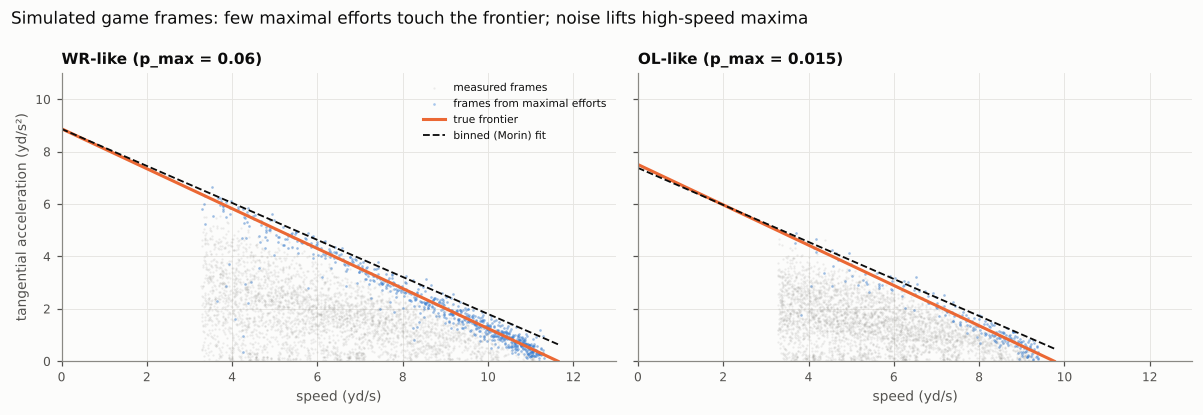

In [5]:
rng=np.random.default_rng(5)
calib={"WR":dict(S0_mean=11.64,S0_sd=0.01,A0_mean=8.89,A0_sd=0.01,p_max=0.06,D_mean=6.5),"OL":dict(S0_mean=9.77,S0_sd=0.01,A0_mean=7.5,A0_sd=0.01,p_max=0.015,D_mean=5.0)}
ath=sample_athletes(rng,1,calib)
out=simulate_game_tracks(ath["A0"],ath["S0"],ath["D"],ath["p_max"],[150,150],GameSimConfig(),rng)
o=np.lexsort((out["t"],out["play"])); out={kk:v[o] for kk,v in out.items()}
s,at,_=kinematics_fast(out["x"],out["y"],out["play"],10,7)
fig,axes=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
for ax,j,lab in zip(axes,(0,1),("WR-like (p_max = 0.06)","OL-like (p_max = 0.015)")):
    m=(out["athlete"]==j)&(s>=V_MIN)&(at>0)
    ax.scatter(s[m],at[m],s=2,alpha=.15,color=style.MUTED,linewidths=0,label="measured frames")
    mx=m&out["maxeff"]; ax.scatter(s[mx],at[mx],s=3,alpha=.4,color=style.SERIES[0],linewidths=0,label="frames from maximal efforts")
    vv=np.linspace(0,ath["S0"][j],50); ax.plot(vv,ath["A0"][j]*(1-vv/ath["S0"][j]),color=style.SERIES[1],lw=2,label="true frontier")
    r=fit_binned(s[out["athlete"]==j],at[out["athlete"]==j],out["play"][out["athlete"]==j])
    ax.plot(vv,r["A0"]*(1-vv/r["S0"]),color=style.TEXT,lw=1.2,ls="--",label="binned (Morin) fit")
    ax.set_title(lab,loc="left",fontsize=10); ax.set_xlabel("speed (yd/s)"); ax.set_xlim(0,13); ax.set_ylim(0,11)
axes[0].set_ylabel("tangential acceleration (yd/s²)"); axes[0].legend(loc="upper right",fontsize=7)
fig.suptitle("Simulated game frames: few maximal efforts touch the frontier; noise lifts high-speed maxima",x=.01,ha="left",fontsize=11)
fig.tight_layout(); save(fig,"generator_scatter")

## 3 · Design history on development seeds (101–103), including what failed
The proposed estimator was not our first design. We report the failed designs because they are informative, and so that the final choice is not mistaken for something we tuned on evaluation data.

| Design | Idea | Development result at realistic noise (σ = 0.01 yd) | Verdict |
|---|---|---|---|
| Bin-maximum frontier with exposure-scaled shortfall (HEF-bin) | bin max = frontier − Exp(λ·n_plays) + one noise term | all estimators biased +50–90% at the initial (unrealistically high) noise of 0.05 yd; coverage 0 | ✗ misspecified: the max of many noisy frames is biased upward |
| Frame-level stochastic frontier (HEF-frame) | every frame = frontier − mixture-exponential shortfall + noise; truncation-corrected | S0 bias +7.7% (vs +17.8% binned) but **A0 bias −22%**; coverage 0.04–0.12; A0 −8.7% even on *perfect* kinematics | ✗ shortfall distribution misspecified |
| Extreme-value bin model (EVT) | P(bin max ≤ y) = CDF_W(y − F)^n | S0 +20%, A0 −11% | ✗ worse than binning |
| Larger smoothing window (7 vs 5 frames) | less differentiation noise | binned S0 bias 15.5% → 5.2% | ✓ preprocessing is first-order |
| SIMEX + quadratic extrapolant, window 7 | remove noise inflation | S0 bias ≈ 2.5%, RMSE ≈ 3.5% | ✓ adopted |
| SIMEX + rational extrapolant | nonlinear extrapolation | unstable (RMSE 14–46%) | ✗ |

The cell below re-runs the key development comparison so these numbers are reproducible (one development seed).

In [6]:
rng=np.random.default_rng(101)
calib2={k:dict(S0_mean=v["S0_mean"],S0_sd=v["S0_sd"],A0_mean=v["A0_mean"],A0_sd=v["A0_sd"],p_max=v["p_max"],D_mean=v["D_mean"]) for k,v in CFG["calib"].items() if k in ("WR","OL")}
ath=sample_athletes(rng,20,calib2)
out=simulate_game_tracks(ath["A0"],ath["S0"],ath["D"],ath["p_max"],np.full(40,100),GameSimConfig(),rng)
o=np.lexsort((out["t"],out["play"])); out={kk:v[o] for kk,v in out.items()}
idx=[np.flatnonzero(out["athlete"]==j) for j in range(40)]
res={}
for w in (5,7):
    s,at,_=kinematics_fast(out["x"],out["y"],out["play"],10,w)
    r=[fit_binned(s[i],at[i],out["play"][i]) for i in idx]; res[f"binned, window {w}"]=(np.array([q["A0"] for q in r]),np.array([q["S0"] for q in r]))
    if w==5:
        h=HierarchicalFrontierEstimator(HEFConfig(mode="frame")).fit([(s[i],at[i],out["play"][i]) for i in idx],ath["pos"]); res["HEF-frame (rejected), window 5"]=(h.A0,h.S0)
        h=HierarchicalFrontierEstimator(HEFConfig(mode="evt")).fit([(s[i],at[i],out["play"][i]) for i in idx],ath["pos"]); res["EVT bins (rejected), window 5"]=(h.A0,h.S0)
r=[fit_simex(out["x"][i],out["y"][i],out["play"][i],noise_sd=0.01,window=7,rng=np.random.default_rng(j)) for j,i in enumerate(idx)]
res["SIMEX (quadratic), window 7"]=(np.array([q["A0"] for q in r]),np.array([q["S0"] for q in r]))
pl.DataFrame([dict(design=k, S0_bias_pct=round(float(np.mean(100*(S-ath["S0"])/ath["S0"])),1), S0_rmse_pct=round(float(np.sqrt(np.mean((100*(S-ath["S0"])/ath["S0"])**2))),1),
                    A0_bias_pct=round(float(np.mean(100*(A-ath["A0"])/ath["A0"])),1), A0_rmse_pct=round(float(np.sqrt(np.mean((100*(A-ath["A0"])/ath["A0"])**2))),1)) for k,(A,S) in res.items()])

design,S0_bias_pct,S0_rmse_pct,A0_bias_pct,A0_rmse_pct
str,f64,f64,f64,f64
"""binned, window 5""",15.0,15.3,1.8,6.3
"""HEF-frame (rejected), window 5""",8.0,8.9,-23.3,24.4
"""EVT bins (rejected), window 5""",16.5,17.2,-10.4,12.1
"""binned, window 7""",5.2,5.4,-1.7,4.3
"""SIMEX (quadratic), window 7""",2.8,3.5,-2.3,5.0


## 4 · Evaluation (disjoint seeds)
**Setup.** 24 cells × 5 replicates × 100 athletes (20 per position). Base cell: 100 plays per athlete, noise 0.01 yd, 10 Hz, window 7.
- Every estimator in a cell uses the **same kinematics** (same window), so differences come from the estimator, not the preprocessing.
- Errors are % of the true value.
- 95% CIs come from 2,000 bootstrap resamples of athletes.

In [7]:
R = R.with_columns((100*(pl.col("S0_hat")-pl.col("S0_true"))/pl.col("S0_true")).alias("eS"),
                   (100*(pl.col("A0_hat")-pl.col("A0_true"))/pl.col("A0_true")).alias("eA"))
ORDER=["max_observed","binned","binned_ci","binned_boxplot","dbscan_binned","quantile_0.99","binned+JK","binned+EB","NCP-AS (SIMEX+JK, no pooling)","NCP-AS"]
def boot_ci(x, f=np.mean, B=2000, seed=0):
    x=np.asarray(x); x=x[np.isfinite(x)]
    if len(x)<5: return (np.nan,np.nan)
    r=np.random.default_rng(seed); b=[f(x[r.integers(0,len(x),len(x))]) for _ in range(B)]
    return np.percentile(b,[2.5,97.5])
def summarise(cell):
    d=R.filter(pl.col("cell")==cell); rows=[]
    for e in ORDER:
        q=d.filter(pl.col("estimator")==e)
        if q.height==0: continue
        eS,eA=q["eS"].to_numpy(),q["eA"].to_numpy()
        rm=lambda z: np.sqrt(np.mean(z**2))
        row=dict(estimator=e, n=q.height, fail_pct=round(100*np.mean(~np.isfinite(eS)|(np.abs(eS)>100)),1),
                 S0_bias=round(np.nanmean(np.where(np.abs(eS)<=100,eS,np.nan)),2), S0_rmse=round(rm(eS[np.abs(eS)<=100]),2),
                 S0_rmse_CI=str(np.round(boot_ci(eS[np.abs(eS)<=100],rm),2)),
                 A0_bias=round(np.nanmean(np.where(np.abs(eA)<=100,eA,np.nan)),2), A0_rmse=round(rm(eA[np.abs(eA)<=100]),2),
                 A0_rmse_CI=str(np.round(boot_ci(eA[np.abs(eA)<=100],rm),2)))
        if "S0_lo" in q.columns and q["S0_lo"].null_count()<q.height:
            row["S0_cov90"]=round(float(((q["S0_lo"]<=q["S0_true"])&(q["S0_true"]<=q["S0_hi"])).mean()),3)
            row["A0_cov90"]=round(float(((q["A0_lo"]<=q["A0_true"])&(q["A0_true"]<=q["A0_hi"])).mean()),3)
            row["S0_width_pct"]=round(float((100*(q["S0_hi"]-q["S0_lo"])/q["S0_true"]).median()),2)
        rows.append(row)
    return pl.DataFrame(rows, infer_schema_length=None)
summarise("base")

estimator,n,fail_pct,S0_bias,S0_rmse,S0_rmse_CI,A0_bias,A0_rmse,A0_rmse_CI,S0_cov90,A0_cov90,S0_width_pct
str,i64,f64,f64,f64,str,f64,f64,str,f64,f64,f64
"""max_observed""",500,0.0,-3.01,3.8,"""[3.47 4.13]""",-19.58,19.96,"""[19.62 20.31]""",0.0,0.0,NaN
"""binned""",500,0.0,5.41,5.56,"""[5.46 5.67]""",-0.83,3.57,"""[3.26 3.88]""",0.0,0.0,NaN
"""binned_ci""",500,0.0,5.27,5.43,"""[5.32 5.54]""",-0.44,3.39,"""[3.07 3.71]""",0.0,0.0,NaN
"""binned_boxplot""",500,0.0,5.65,5.89,"""[5.75 6.03]""",-3.23,5.27,"""[4.93 5.59]""",0.0,0.0,NaN
"""dbscan_binned""",500,0.0,7.97,8.54,"""[8.3 8.78]""",-12.73,15.37,"""[14.75 15.99]""",0.0,0.0,NaN
"""quantile_0.99""",500,0.0,7.12,7.5,"""[7.22 7.78]""",-3.78,5.99,"""[5.51 6.45]""",0.0,0.0,NaN
"""binned+JK""",500,0.0,5.41,5.56,"""[5.46 5.67]""",-0.83,3.57,"""[3.26 3.88]""",0.042,0.758,3.29
"""binned+EB""",500,0.0,5.36,5.51,"""[5.41 5.62]""",-0.76,3.89,"""[3.52 4.29]""",0.034,0.724,3.16
"""NCP-AS (SIMEX+JK, no pooling)""",500,0.0,2.79,3.65,"""[3.44 3.87]""",-1.46,4.58,"""[4.21 4.94]""",0.958,0.976,14.96


Failures (non-finite fits, or |error| > 100%) are counted separately and excluded from bias/RMSE; `fail_pct` reports them.

### 4.1 Paired comparison: is NCP-AS better than the same-preprocessing Morin baseline?

In [8]:
def paired(cell, a="NCP-AS", b="binned", target="eS"):
    d=R.filter(pl.col("cell")==cell)
    x=d.filter(pl.col("estimator")==a).select("rep","athlete",pl.col(target).alias("ea"))
    y=d.filter(pl.col("estimator")==b).select("rep","athlete",pl.col(target).alias("eb"))
    j=x.join(y,on=["rep","athlete"]).filter(pl.col("ea").is_finite()&pl.col("eb").is_finite()&(pl.col("ea").abs()<=100)&(pl.col("eb").abs()<=100))
    diff=(j["ea"]**2-j["eb"]**2).to_numpy()
    lo,hi=boot_ci(diff)
    return dict(cell=cell, target="S0" if target=="eS" else "A0", comparison=f"{a} − {b}", n=len(diff),
                mean_diff_sq_err=round(float(diff.mean()),2), CI95=f"[{lo:.2f}, {hi:.2f}]",
                verdict="NCP-AS better" if hi<0 else ("NCP-AS worse" if lo>0 else "no significant difference"))
cells=[c for c in R["cell"].unique(maintain_order=True).to_list() if R.filter((pl.col("cell")==c)&(pl.col("estimator")=="NCP-AS")).height>0]
comp=pl.DataFrame([paired(c,target=t) for c in cells for t in ("eS","eA")]); comp

cell,target,comparison,n,mean_diff_sq_err,CI95,verdict
str,str,str,i64,f64,str,str
"""base""","""S0""","""NCP-AS − binned""",500,-13.84,"""[-16.08, -11.28]""","""NCP-AS better"""
"""base""","""A0""","""NCP-AS − binned""",500,37.79,"""[27.59, 50.10]""","""NCP-AS worse"""
"""exposure_10""","""S0""","""NCP-AS − binned""",500,-33.65,"""[-41.49, -26.47]""","""NCP-AS better"""
"""exposure_10""","""A0""","""NCP-AS − binned""",500,-4.29,"""[-36.73, 26.18]""","""no significant difference"""
"""exposure_25""","""S0""","""NCP-AS − binned""",500,-7.64,"""[-11.62, -3.38]""","""NCP-AS better"""
"""exposure_25""","""A0""","""NCP-AS − binned""",500,11.11,"""[-4.14, 26.27]""","""no significant difference"""
"""exposure_50""","""S0""","""NCP-AS − binned""",500,-7.52,"""[-10.41, -4.38]""","""NCP-AS better"""
"""exposure_50""","""A0""","""NCP-AS − binned""",500,40.88,"""[30.65, 52.01]""","""NCP-AS worse"""
"""exposure_250""","""S0""","""NCP-AS − binned""",500,-23.68,"""[-25.87, -21.40]""","""NCP-AS better"""


The table reports the difference in squared % error (NCP-AS minus binned) for each athlete. A negative value means NCP-AS is closer to the truth.
- "Better" is claimed **only if the 95% CI excludes 0**, and only *within this simulation*.

**Further paired comparisons** (all cells; squared-% error; 95% bootstrap CI):
- the unpooled variant against binning;
- both NCP-AS variants against the naive maximum observed speed, which is a strong S0 competitor because speed needs no second derivative.

In [9]:
extra=[]
for c in cells:
    for a_,b_ in [("NCP-AS (SIMEX+JK, no pooling)","binned"),("NCP-AS (SIMEX+JK, no pooling)","max_observed"),("NCP-AS","max_observed")]:
        extra.append(paired(c,a=a_,b=b_,target="eS"))
    extra.append(paired(c,a="NCP-AS (SIMEX+JK, no pooling)",b="binned",target="eA"))
ex=pl.DataFrame(extra)
print(ex.group_by("comparison","target","verdict").len().sort("comparison","target","verdict"))
ex.filter(pl.col("cell").is_in(["base","exposure_10","exposure_25","pmax_0.25","mixed_exposure","noise_0.02","spike_0.03"]))

┌─────────────────────────────────┬────────┬───────────────────────────┬─────┐
│ comparison                      ┆ target ┆ verdict                   ┆ len │
│ ---                             ┆ ---    ┆ ---                       ┆ --- │
│ str                             ┆ str    ┆ str                       ┆ u32 │
╞═════════════════════════════════╪════════╪═══════════════════════════╪═════╡
│ NCP-AS (SIMEX+JK, no pooling) … ┆ A0     ┆ NCP-AS better             ┆ 1   │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ A0     ┆ NCP-AS worse              ┆ 16  │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ A0     ┆ no significant difference ┆ 6   │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ S0     ┆ NCP-AS better             ┆ 21  │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ S0     ┆ no significant difference ┆ 2   │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ S0     ┆ NCP-AS better             ┆ 11  │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ S0     ┆ NCP-AS worse              ┆ 10  │
│ NCP-AS (SIMEX+JK, no pooling) … ┆ S0     ┆ no sign

cell,target,comparison,n,mean_diff_sq_err,CI95,verdict
str,str,str,i64,f64,str,str
"""base""","""S0""","""NCP-AS (SIMEX+JK, no pooling) …",500,-17.6,"""[-19.11, -16.12]""","""NCP-AS better"""
"""base""","""S0""","""NCP-AS (SIMEX+JK, no pooling) …",500,-1.09,"""[-3.67, 1.21]""","""no significant difference"""
"""base""","""S0""","""NCP-AS − max_observed""",500,2.67,"""[-0.60, 6.09]""","""no significant difference"""
"""base""","""A0""","""NCP-AS (SIMEX+JK, no pooling) …",500,8.17,"""[5.94, 10.45]""","""NCP-AS worse"""
"""exposure_10""","""S0""","""NCP-AS (SIMEX+JK, no pooling) …",500,-3.08,"""[-8.63, 2.65]""","""no significant difference"""
"""exposure_10""","""S0""","""NCP-AS (SIMEX+JK, no pooling) …",500,-65.13,"""[-79.93, -49.72]""","""NCP-AS better"""
"""exposure_10""","""S0""","""NCP-AS − max_observed""",500,-95.7,"""[-111.99, -80.39]""","""NCP-AS better"""
"""exposure_10""","""A0""","""NCP-AS (SIMEX+JK, no pooling) …",500,2.43,"""[-9.87, 15.44]""","""no significant difference"""
"""exposure_25""","""S0""","""NCP-AS (SIMEX+JK, no pooling) …",500,-10.14,"""[-12.43, -7.64]""","""NCP-AS better"""


### 4.2 Sensitivity to the amount of tracking data (exposure)

plays,estimator,fail_pct,S0_bias,S0_rmse,A0_bias,A0_rmse,S0_cov90,A0_cov90
i32,str,f64,f64,f64,f64,f64,f64,f64
10,"""binned""",0.0,4.56,7.45,-18.86,20.78,0.0,0.0
10,"""binned+EB""",0.0,3.86,5.75,-19.12,20.83,0.554,0.148
10,"""NCP-AS""",0.0,1.74,4.68,-18.41,20.68,0.284,0.136
25,"""binned""",0.0,4.98,5.69,-9.5,11.51,0.0,0.0
25,"""binned+EB""",0.0,4.83,5.51,-9.23,11.47,0.23,0.446
25,"""NCP-AS""",0.0,2.64,4.97,-7.91,11.98,0.256,0.416
50,"""binned""",0.0,4.91,5.22,-3.66,5.99,0.0,0.0
50,"""binned+EB""",0.0,4.88,5.16,-3.58,6.22,0.106,0.692
50,"""NCP-AS""",0.0,2.22,4.44,-2.55,8.76,0.396,0.63


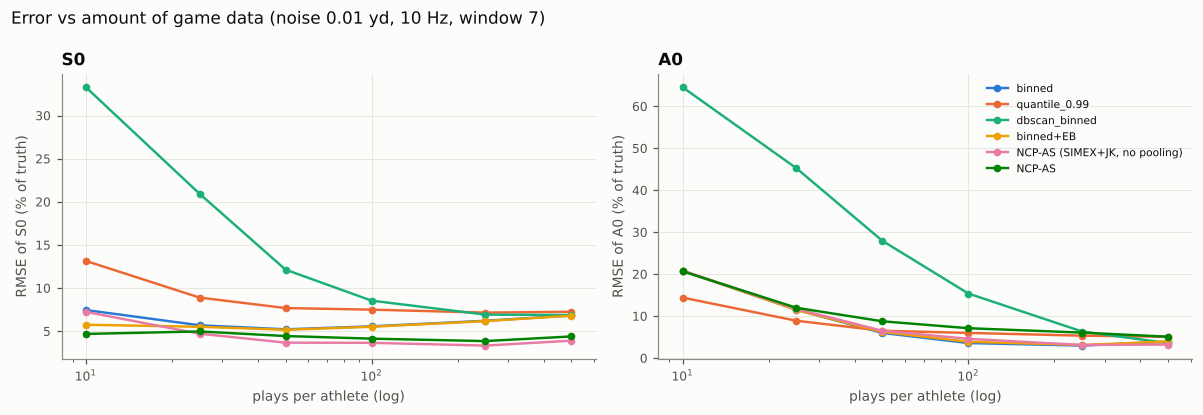

In [10]:
expo={10:"exposure_10",25:"exposure_25",50:"exposure_50",100:"base",250:"exposure_250",500:"exposure_500"}
show=["binned","quantile_0.99","dbscan_binned","binned+EB","NCP-AS (SIMEX+JK, no pooling)","NCP-AS"]
colors=dict(zip(show,style.SERIES))
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
for ax,t,lab in zip(axes,("eS","eA"),("S0","A0")):
    for e in show:
        y=[];
        for n,c in expo.items():
            q=R.filter((pl.col("cell")==c)&(pl.col("estimator")==e))[t].to_numpy(); q=q[np.isfinite(q)&(np.abs(q)<=100)]
            y.append(np.sqrt(np.mean(q**2)) if len(q) else np.nan)
        ax.plot(list(expo),y,marker="o",ms=4,color=colors[e],label=e)
    ax.set_xscale("log"); ax.set_xlabel("plays per athlete (log)"); ax.set_ylabel(f"RMSE of {lab} (% of truth)"); ax.set_title(f"{lab}",loc="left")
axes[1].legend(fontsize=7,loc="upper right")
fig.suptitle("Error vs amount of game data (noise 0.01 yd, 10 Hz, window 7)",x=.01,ha="left",fontsize=11)
fig.tight_layout(); save(fig,"exposure")
pl.concat([summarise(c).with_columns(pl.lit(n).alias("plays")) for n,c in expo.items()], how="diagonal_relaxed").filter(pl.col("estimator").is_in(["binned","NCP-AS","binned+EB"])).select("plays","estimator","fail_pct","S0_bias","S0_rmse","A0_bias","A0_rmse","S0_cov90","A0_cov90")

### 4.3 Sensitivity to measurement noise, smoothing window and sampling rate

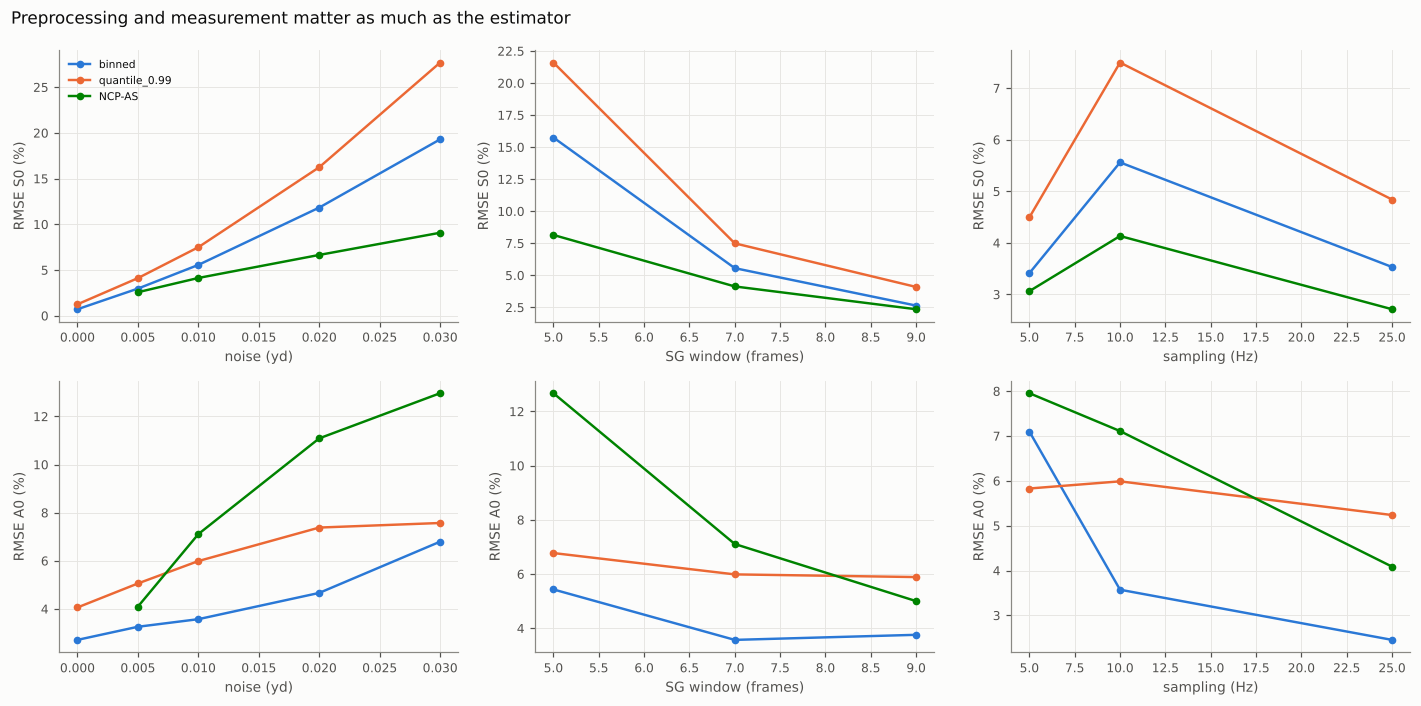

In [11]:
groups={"noise (yd)":{0.0:"noise_0.0",0.005:"noise_0.005",0.01:"base",0.02:"noise_0.02",0.03:"noise_0.03"},
        "SG window (frames)":{5:"window_5",7:"base",9:"window_9"},
        "sampling (Hz)":{5:"fs_5",10:"base",25:"fs_25"}}
fig,axes=plt.subplots(2,3,figsize=(13,6.5))
for col,(gname,mp) in enumerate(groups.items()):
    for row,t in enumerate(("eS","eA")):
        ax=axes[row,col]
        for e in ["binned","quantile_0.99","NCP-AS"]:
            ys=[]
            for k,c in mp.items():
                q=R.filter((pl.col("cell")==c)&(pl.col("estimator")==e))[t].to_numpy(); q=q[np.isfinite(q)&(np.abs(q)<=100)]
                ys.append(np.sqrt(np.mean(q**2)) if len(q) else np.nan)
            ax.plot(list(mp),ys,marker="o",ms=4,color=colors.get(e,style.SERIES[0]),label=e)
        ax.set_xlabel(gname); ax.set_ylabel(f"RMSE {'S0' if t=='eS' else 'A0'} (%)")
axes[0,0].legend(fontsize=7)
fig.suptitle("Preprocessing and measurement matter as much as the estimator",x=.01,ha="left",fontsize=11)
fig.tight_layout(); save(fig,"noise_window_fs")

Notes on these cells:
- At noise = 0, SIMEX is undefined, so NCP-AS is absent from that cell.
- The 5 Hz and 25 Hz cells use windows of 5 and 17 frames (about 1.0 s and 0.7 s).

### 4.4 Robustness: opportunity, frontier shape, tracking faults, wrong noise SD, heterogeneous exposure

In [12]:
rob=["pmax_0.25","pmax_0.5","base","pmax_2.0","shape_0.8","shape_1.3","spike_0.01","spike_0.03","simex_sd_x0.5","simex_sd_x1.5","mixed_exposure"]
tab=pl.concat([summarise(c).with_columns(pl.lit(c).alias("cell")) for c in rob], how="diagonal_relaxed").filter(pl.col("estimator").is_in(["binned","quantile_0.99","dbscan_binned","binned+EB","NCP-AS"]))
tab.select("cell","estimator","fail_pct","S0_bias","S0_rmse","A0_bias","A0_rmse","S0_cov90","A0_cov90")

cell,estimator,fail_pct,S0_bias,S0_rmse,A0_bias,A0_rmse,S0_cov90,A0_cov90
str,str,f64,f64,f64,f64,f64,f64,f64
"""pmax_0.25""","""binned""",0.0,4.47,4.76,-5.63,6.95,0.0,0.0
"""pmax_0.25""","""dbscan_binned""",0.0,6.56,7.3,-20.7,21.1,0.0,0.0
"""pmax_0.25""","""quantile_0.99""",0.0,7.27,7.72,-10.48,11.59,0.0,0.0
"""pmax_0.25""","""binned+EB""",0.0,4.32,4.63,-5.61,7.13,0.136,0.494
"""pmax_0.25""","""NCP-AS""",0.0,1.71,4.06,-4.65,8.91,0.416,0.616
"""pmax_0.5""","""binned""",0.0,4.96,5.18,-3.44,5.42,0.0,0.0
"""pmax_0.5""","""dbscan_binned""",0.0,7.76,8.38,-18.59,19.68,0.0,0.0
"""pmax_0.5""","""quantile_0.99""",0.0,7.34,7.71,-7.39,9.12,0.0,0.0
"""pmax_0.5""","""binned+EB""",0.0,4.86,5.08,-3.27,5.5,0.076,0.668


Notes on these cells:
- **shape_k:** the true frontier is A0(1 − (v/S0)^k), so every *linear* estimator is misspecified when k ≠ 1. The truth is still defined as the intercept A0 and the zero-crossing S0.
- **simex_sd_x:** SIMEX is given a noise SD that is 0.5× or 1.5× the true value.
- **spike:** a share of plays contains a burst of 2–5 corrupted frames, like the faulty 2025 game.

### 4.5 Calibration of the interval estimates

estimator,median_S0_cov,min_S0_cov,median_A0_cov,min_A0_cov
str,f64,f64,f64,f64
"""NCP-AS (SIMEX+JK, no pooling)""",0.97,0.512,0.952,0.396
"""NCP-AS""",0.414,0.016,0.662,0.136
"""binned+EB""",0.066,0.0,0.575,0.016
"""binned+JK""",0.079,0.0,0.667,0.014


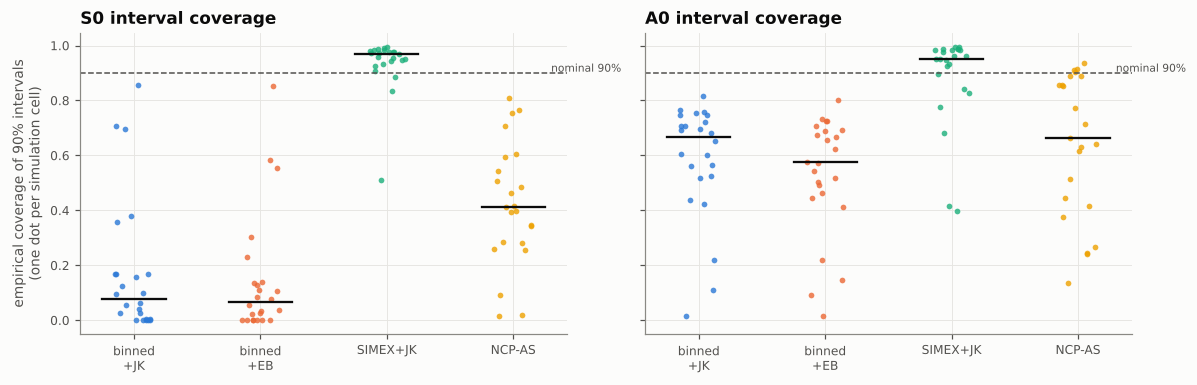

In [13]:
cal=[]
for c in R["cell"].unique(maintain_order=True).to_list():
    for e in ["binned+JK","binned+EB","NCP-AS (SIMEX+JK, no pooling)","NCP-AS"]:
        q=R.filter((pl.col("cell")==c)&(pl.col("estimator")==e))
        if q.height==0: continue
        cal.append(dict(cell=c,estimator=e,S0_cov=float(((q["S0_lo"]<=q["S0_true"])&(q["S0_true"]<=q["S0_hi"])).mean()),
                        A0_cov=float(((q["A0_lo"]<=q["A0_true"])&(q["A0_true"]<=q["A0_hi"])).mean())))
cal=pl.DataFrame(cal)
fig,axes=plt.subplots(1,2,figsize=(11,3.6),sharey=True)
ests=["binned+JK","binned+EB","NCP-AS (SIMEX+JK, no pooling)","NCP-AS"]
for ax,t in zip(axes,("S0_cov","A0_cov")):
    for i,e in enumerate(ests):
        v=cal.filter(pl.col("estimator")==e)[t].to_numpy()
        ax.scatter(np.full(len(v),i)+np.random.default_rng(i).uniform(-.15,.15,len(v)),v,s=14,color=style.SERIES[i],alpha=.8,linewidths=0)
        ax.plot([i-.25,i+.25],[np.median(v)]*2,color=style.TEXT,lw=1.5)
    ax.axhline(0.9,color=style.TEXT2,ls="--",lw=1); ax.text(3.3,0.905,"nominal 90%",fontsize=7,color=style.TEXT2)
    ax.set_xticks(range(len(ests)),["binned\n+JK","binned\n+EB","SIMEX+JK","NCP-AS"],fontsize=8); ax.set_title(t.replace("_cov"," interval coverage"),loc="left")
axes[0].set_ylabel("empirical coverage of 90% intervals\n(one dot per simulation cell)")
fig.tight_layout(); save(fig,"calibration")
cal.group_by("estimator").agg(pl.col("S0_cov").median().round(3).alias("median_S0_cov"),pl.col("S0_cov").min().round(3).alias("min_S0_cov"),
                              pl.col("A0_cov").median().round(3).alias("median_A0_cov"),pl.col("A0_cov").min().round(3).alias("min_A0_cov"))

### 4.6 Where does the remaining error come from? (censoring diagnostics)

In [14]:
q=R.filter((pl.col("cell")=="mixed_exposure")&pl.col("estimator").is_in(["binned","NCP-AS"])).with_columns(
    pl.when(pl.col("n_plays_ge95")==0).then(pl.lit("0 plays ≥95% S0")).when(pl.col("n_plays_ge95")<=3).then(pl.lit("1–3")).otherwise(pl.lit(">3")).alias("near_max_exposure"))
q.group_by("estimator","near_max_exposure").agg(pl.len().alias("n"),pl.col("eS").mean().round(2).alias("S0_bias"),(pl.col("eS")**2).mean().sqrt().round(2).alias("S0_rmse"),
    pl.col("eA").mean().round(2).alias("A0_bias"),(pl.col("eA")**2).mean().sqrt().round(2).alias("A0_rmse")).sort("estimator","near_max_exposure")

estimator,near_max_exposure,n,S0_bias,S0_rmse,A0_bias,A0_rmse
str,str,u32,f64,f64,f64,f64
"""NCP-AS""","""0 plays ≥95% S0""",40,1.62,4.4,2.51,10.85
"""NCP-AS""","""1–3""",110,1.91,4.43,-0.13,9.07
"""NCP-AS""",""">3""",350,3.38,4.5,0.25,4.18
"""binned""","""0 plays ≥95% S0""",40,4.14,5.88,-6.46,12.23
"""binned""","""1–3""",110,5.81,6.08,-3.15,8.74
"""binned""",""">3""",350,6.35,6.44,2.09,3.56


Uses the realistic (mixed) exposure cell, split by how many plays truly reached ≥ 95% of S0. This is truth-only information, unavailable to any estimator.

## 5 · Conclusions (simulation only)
See `research_notes/candidate_b_feasibility.md` for the narrative interpretation, the assumptions that cannot be validated, and the recommendation. The numbers there are taken from the tables above.